## **Homework 03 - Stock Markets Analytics -  Zoomcamp 2026**

## **Imports**

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.impute import SimpleImputer
from sklearn.metrics import precision_score

## **Question 01**

- **Problem statement: What is the ABSOLUTE CORRELATION VALUE of the most correlated dummy variable **week_of_month_** with the binary outcome is_positive_growth_30d_future?**

### **Solution**

In [2]:
df = pd.read_parquet("data/stocks_df_combined.parquet.brotli")

df = df[df.Date >= "2000-01-01"].reset_index(drop=True)

In [3]:
df["wom"] = (df["Date"].dt.day - 1) // 7 + 1

df.groupby("Month").agg(
    unique_wom=("wom", "nunique"),
    first_day=("Date", "min"),
    last_day=("Date", "max"),
)

,unique_wom,first_day,last_day
Month,,,
2000-01-01,5,2000-01-03,2000-01-31
2000-02-01,5,2000-02-01,2000-02-29
2000-03-01,5,2000-03-01,2000-03-31
2000-04-01,4,2000-04-03,2000-04-28
2000-05-01,5,2000-05-01,2000-05-31
...,...,...,...
2026-05-01,5,2026-05-01,2026-05-29
2026-06-01,5,2026-06-01,2026-06-30
2026-07-01,5,2026-07-01,2026-07-31


In [4]:
df[["Month", "wom"]].head()

,Month,wom
0,2000-01-01,1
1,2000-01-01,1
2,2000-01-01,1
3,2000-01-01,1
4,2000-01-01,1


In [5]:
df["month_wom"] = df["Date"].dt.month_name() + "_w" + df["wom"].astype(str)

df[["Month", "wom", "month_wom"]].head()


,Month,wom,month_wom
0,2000-01-01,1,January_w1
1,2000-01-01,1,January_w1
2,2000-01-01,1,January_w1
3,2000-01-01,1,January_w1
4,2000-01-01,1,January_w1


In [6]:
CATEGORICAL = ["Month", "Weekday", "Ticker", "ticker_type", "month_wom"]

df_categorical = df[CATEGORICAL].copy()
df_categorical["Month"] = df_categorical["Month"].dt.month.astype(str)
df_categorical["Weekday"] = df_categorical["Weekday"].astype(str)

dummy_variables = pd.get_dummies(df_categorical, dtype="int32")
DUMMIES = dummy_variables.keys().to_list()

df_with_dummies = pd.concat([df, dummy_variables], axis=1)

In [7]:
TO_PREDICT = [g for g in df.keys() if g.find("future") >= 0]
TO_PREDICT

['growth_future_30d', 'is_positive_growth_30d_future']

In [8]:
corr = df_with_dummies[DUMMIES + TO_PREDICT].corr()["is_positive_growth_30d_future"]
corr

Month_1                         -0.040014
Month_10                         0.035999
Month_11                         0.035443
Month_12                        -0.010303
Month_2                         -0.027313
                                   ...   
month_wom_September_w3          -0.009193
month_wom_September_w4           0.014618
month_wom_September_w5           0.013410
growth_future_30d                0.698218
is_positive_growth_30d_future    1.000000
Name: is_positive_growth_30d_future, Length: 117, dtype: float64

In [9]:
df_corr_filtered = pd.DataFrame(corr.filter(like="month_wom_"))

df_corr_filtered["abs_corr"] = df_corr_filtered["is_positive_growth_30d_future"].abs().round(3)

df_corr_filtered_sorted = df_corr_filtered.sort_values(by="abs_corr", ascending=False)

df_corr_filtered_sorted.head()

,is_positive_growth_30d_future,abs_corr
month_wom_October_w4,0.024584,0.025
month_wom_November_w3,0.023251,0.023
month_wom_February_w1,-0.020861,0.021
month_wom_January_w2,-0.019846,0.020
month_wom_January_w5,-0.019792,0.020


> **Answer:** The most correlated dummy variable with the binary target `is_positive_growth_30d_future` is the `month_wom_October_w4`, presenting a absolute correlation of 0.025.

## **Question 02**

- **Problem statement: What is the precision score for the best of the NEW predictions (pred3 or pred4), rounded to 3 decimal places?**

### **Solution**

In [10]:
def temporal_split(df, min_date, max_date, train_prop=0.7, val_prop=0.15, test_prop=0.15):
    """
    Splits a DataFrame into three buckets based on the temporal order of the 'Date' column.

    Args:
        df (DataFrame): The DataFrame to split.
        min_date (str or Timestamp): Minimum date in the DataFrame.
        max_date (str or Timestamp): Maximum date in the DataFrame.
        train_prop (float): Proportion of data for training set (default: 0.6).
        val_prop (float): Proportion of data for validation set (default: 0.2).
        test_prop (float): Proportion of data for test set (default: 0.2).

    Returns:
        DataFrame: The input DataFrame with a new column 'split' indicating the split for each row.
    """
    # Define the date intervals
    train_end = min_date + pd.Timedelta(days=(max_date - min_date).days * train_prop)
    val_end = train_end + pd.Timedelta(days=(max_date - min_date).days * val_prop)

    # Assign split labels based on date ranges
    split_labels = []
    for date in df['Date']:
        if date <= train_end:
            split_labels.append('train')
        elif date <= val_end:
            split_labels.append('val')
        else:
            split_labels.append('test')

    # Add 'split' column to the DataFrame
    df['split'] = split_labels

    return df

In [11]:
min_date_df = df_with_dummies.Date.min()
max_date_df = df_with_dummies.Date.max()

df_with_dummies = temporal_split(df_with_dummies,
                                 min_date = min_date_df,
                                 max_date = max_date_df)

In [12]:
df_new = df_with_dummies.copy()

df_new["pred0_manual_cci"] = (df_new.cci > 200).astype(int)
df_new["pred1_manual_prev_g1"] = (df_new.growth_30d > 1).astype(int)
df_new["pred2_manual_prev_g1_and_snp"] = (
    (df_new["growth_30d"] > 1) & (df_new["growth_snp500_30d"] > 1)
).astype(int)
df_new["pred3_manual_dgs10_5"] = (
    (df_new["DGS10"] <= 4.5) & (df_new["DGS5"] <= 4)
).astype(int)
df_new["pred4_manual_dgs10_fedfunds"] = (
    (df_new["DGS10"] > 4) & (df_new["FEDFUNDS"] <= 4.795)
).astype(int)

PREDICTIONS = [k for k in df_new.keys() if k.startswith("pred")]


In [13]:
df_new_train = df_new[df_new["split"] == "train"]
df_new_val = df_new[df_new["split"] == "val"]
df_new_test = df_new[df_new["split"] == "test"]

assert(len(df_new_train) + len(df_new_val) + len(df_new_test) == len(df_with_dummies))

In [14]:
df_manual_test = df_new_test[PREDICTIONS + [TO_PREDICT[1]]]
df_manual_test.head()

,pred0_manual_cci,pred1_manual_prev_g1,pred2_manual_prev_g1_and_snp,pred3_manual_dgs10_5,pred4_manual_dgs10_fedfunds,is_positive_growth_30d_future
5713,0,0,0,1,0,0
5714,0,0,0,1,0,0
5715,0,0,0,1,0,0
5716,0,0,0,1,0,0
5717,0,0,0,1,0,0


In [15]:
df_manual_test['is_correct_pred3'] = (df_manual_test.pred3_manual_dgs10_5 == df_manual_test.is_positive_growth_30d_future)
df_manual_test['is_correct_pred4'] = (df_manual_test.pred4_manual_dgs10_fedfunds == df_manual_test.is_positive_growth_30d_future)

In [16]:
df_manual_test[[
    "pred3_manual_dgs10_5", "pred4_manual_dgs10_fedfunds", 
    "is_correct_pred3", "is_correct_pred4", "is_positive_growth_30d_future"]]

,pred3_manual_dgs10_5,pred4_manual_dgs10_fedfunds,is_correct_pred3,is_correct_pred4,is_positive_growth_30d_future
5713,1,0,False,True,0
5714,1,0,False,True,0
5715,1,0,False,True,0
5716,1,0,False,True,0
5717,1,0,False,True,0
...,...,...,...,...,...
202287,0,1,True,False,0
202288,0,1,True,False,0
202289,0,1,True,False,0
202290,0,1,True,False,0


In [17]:
df_precision_pred3 = df_manual_test[df_manual_test.pred3_manual_dgs10_5 == 1]

tp = (df_precision_pred3["is_correct_pred3"] == True).sum()
fp = (df_precision_pred3["is_correct_pred3"] == False).sum()

tp / (tp + fp)

np.float64(0.5877435575109994)

In [18]:
df_precision_pred4 = df_manual_test[df_manual_test.pred4_manual_dgs10_fedfunds == 1]

tp = (df_precision_pred4["is_correct_pred4"] == True).sum()
fp = (df_precision_pred4["is_correct_pred4"] == False).sum()

tp / (tp + fp)

np.float64(0.5025438100621821)

In [19]:
df_manual_test[df_manual_test.pred3_manual_dgs10_5 == 1].is_correct_pred3.value_counts(normalize=True).round(3)


is_correct_pred3
True     0.588
False    0.412
Name: proportion, dtype: float64

In [20]:
df_manual_test[df_manual_test.pred4_manual_dgs10_fedfunds == 1].is_correct_pred4.value_counts(normalize=True)

is_correct_pred4
True     0.502544
False    0.497456
Name: proportion, dtype: float64

> **Answer:** The variable `pred3` presents the best precision score: 0.588.

## **Question 03**

- **Problem statement:What is the optimal tree depth (from 1 to 12) for a DecisionTreeClassifier?**

### **Solution**

### **Define the numerical features**

In [21]:
# manually defined features
CUSTOM_NUMERICAL = ['SMA10', 'SMA20', 'growing_moving_average', 'high_minus_low_relative','volatility', 'ln_volume']

TECHNICAL_INDICATORS = ['adx', 'adxr', 'apo', 'aroon_1','aroon_2', 'aroonosc',
 'bop', 'cci', 'cmo','dx', 'macd', 'macdsignal', 'macdhist', 'macd_ext',
 'macdsignal_ext', 'macdhist_ext', 'macd_fix', 'macdsignal_fix',
 'macdhist_fix', 'mfi', 'minus_di', 'mom', 'plus_di', 'dm', 'ppo',
 'roc', 'rocp', 'rocr', 'rocr100', 'rsi', 'slowk', 'slowd', 'fastk',
 'fastd', 'fastk_rsi', 'fastd_rsi', 'trix', 'ultosc', 'willr',
 'ad', 'adosc', 'obv', 'atr', 'natr', 'ht_dcperiod', 'ht_dcphase',
 'ht_phasor_inphase', 'ht_phasor_quadrature', 'ht_sine_sine', 'ht_sine_leadsine',
 'ht_trendmod', 'avgprice', 'medprice', 'typprice', 'wclprice']

TECHNICAL_PATTERNS = [g for g in df.keys() if g.find('cdl')>=0]

MACRO = ['gdppot_us_yoy', 'gdppot_us_qoq', 'cpi_core_yoy', 'cpi_core_mom', 'FEDFUNDS',
 'DGS1', 'DGS5', 'DGS10']

# growth indicators (but not future growth)
GROWTH = [g for g in df.keys() if (g.find('growth_')==0)&(g.find('future')<0)]

NUMERICAL = GROWTH + TECHNICAL_INDICATORS + TECHNICAL_PATTERNS + CUSTOM_NUMERICAL + MACRO

#### **Preprocess data and build X and y**

In [22]:
df_new["ln_volume"] = df_new.Volume.replace(0, np.nan).fillna(1e-9).apply(np.log)

In [23]:
features_list = NUMERICAL + DUMMIES
to_predict = "is_positive_growth_30d_future"

# Feature matrix with same rows as df_new
X_all = df_new[features_list].replace([np.inf, -np.inf], np.nan).fillna(0)
y_all = df_new[to_predict]

# full_train = train + val
is_full_train = df_new["split"].isin(["train", "val"])
X_train, y_train = X_all[is_full_train], y_all[is_full_train]

### **Train the Decision Tree**

In [24]:
dt_10 = DecisionTreeClassifier(max_depth=10, random_state=42)

dt_10.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples i

- **Following the hint to predict on the entire dataset to facilitate**

In [25]:
df_new["pred5_dt_10"] = dt_10.predict(X_all)

PREDICTIONS = [k for k in df_new.keys() if k.startswith("pred")]


In [26]:
for pred in PREDICTIONS:
    part1 = pred.split("_")[0]
    df_new[f"is_correct_{part1}"] = (df_new[pred] == df_new[to_predict]).astype(int)

hand_rules = [f"is_correct_pred{i}" for i in range(5)]

# df_new["only_pred5_is_correct"] = (
#     (df_new["is_correct_pred5"] == 1) & (df_new[hand_rules].sum(axis=1) == 0)
# )

df_new["only_pred5_is_correct"] = (
    (df_new["is_correct_pred5"] == 1)
    & (df_new[to_predict] == 1)
    & (df_new[hand_rules].sum(axis=1) == 0)
)


df_new.filter(like="pred")

,pred0_manual_cci,pred1_manual_prev_g1,pred2_manual_prev_g1_and_snp,pred3_manual_dgs10_5,pred4_manual_dgs10_fedfunds,pred5_dt_10,is_correct_pred0,is_correct_pred1,is_correct_pred2,is_correct_pred3,is_correct_pred4,is_correct_pred5,only_pred5_is_correct
0,0,1,1,0,0,0,1,0,0,1,1,1,False
1,0,1,0,0,0,1,1,0,1,1,1,0,False
2,0,1,0,0,0,1,1,0,1,1,1,0,False
3,0,1,0,0,0,0,1,0,1,1,1,1,False
4,0,1,1,0,0,0,1,0,0,1,1,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
202287,0,0,0,0,1,0,1,1,1,1,0,1,False
202288,0,0,0,0,1,0,1,1,1,1,0,1,False
202289,0,0,0,0,1,0,1,1,1,1,0,1,False
202290,0,0,0,0,1,0,1,1,1,1,0,1,False


In [27]:
df_new["only_pred5_is_correct"] = df_new["only_pred5_is_correct"].astype(int)

df_new[df_new.split == "test"]["only_pred5_is_correct"].sum()

np.int64(1187)

> **Answer:** There are **1187** test instances where only pred5 is correct.

#### **Extra: apply**

In [28]:
# IS_CORRECT = [k for k in df_new.keys() if k.startswith("is_correct_")]


# def is_uniquely_correct(row, target_col):
#     """1 se a previsão de target_col acertou e todas as outras erraram."""
#     others = [c for c in row.index if c != target_col]
#     return int(row[target_col] == 1 and row[others].sum() == 0)


# for col in IS_CORRECT:
#     part1 = col.replace("is_correct_", "")  # 'pred0', 'pred1', ...
#     df_new[f"only_{part1}_is_correct_apply"] = df_new[IS_CORRECT].apply(
#         is_uniquely_correct, axis=1, target_col=col
#     )

# # confere com a versão vetorizada
# assert (df_new["only_pred5_is_correct_apply"] == df_new["only_pred5_is_correct"]).all()

# ONLY = [f"only_pred{i}_is_correct_apply" for i in range(6)]
# df_new[df_new.split == "test"][ONLY].sum()


## **Question 04**

- **Problem statement: What is the optimal tree depth (from 1 to 12) for a DecisionTreeClassifier?**

### **Solution**

#### **Train, validation and test splitting**

This time, a separated validation set is required in order to decide on `max_depth` hyperparameter!

In [29]:
is_train = df_new["split"] == "train"
is_val = df_new["split"] == "val"
is_test = df_new["split"] == "test"

X_tr, y_tr = X_all[is_train], y_all[is_train]
X_val, y_val = X_all[is_val], y_all[is_val]
X_test, y_test = X_all[is_test], y_all[is_test]

assert len(X_tr) + len(X_val) + len(X_test) == len(df_new)


#### **Hyperparameter tuning**

In [30]:
trees = {}
results = []

for max_depth in range(1, 13):
    clf = DecisionTreeClassifier(max_depth=max_depth, random_state=42)
    clf.fit(X_tr, y_tr)
    trees[max_depth] = clf
    results.append({
        "max_depth": max_depth,
        "precision_train": precision_score(y_tr, clf.predict(X_tr)),
        "precision_val": precision_score(y_val, clf.predict(X_val)),
    })

df_tuning = pd.DataFrame(results).set_index("max_depth")
best_max_depth = int(df_tuning["precision_val"].idxmax())

print(f"best_max_depth = {best_max_depth}")
df_tuning.round(4)


best_max_depth = 4


,precision_train,precision_val
max_depth,,
1,0.6206,0.6491
2,0.6195,0.6491
3,0.6283,0.6439
4,0.6450,0.6595
5,0.6502,0.6439
6,0.6678,0.6054
7,0.6874,0.6118
8,0.6937,0.6174
9,0.7116,0.6166


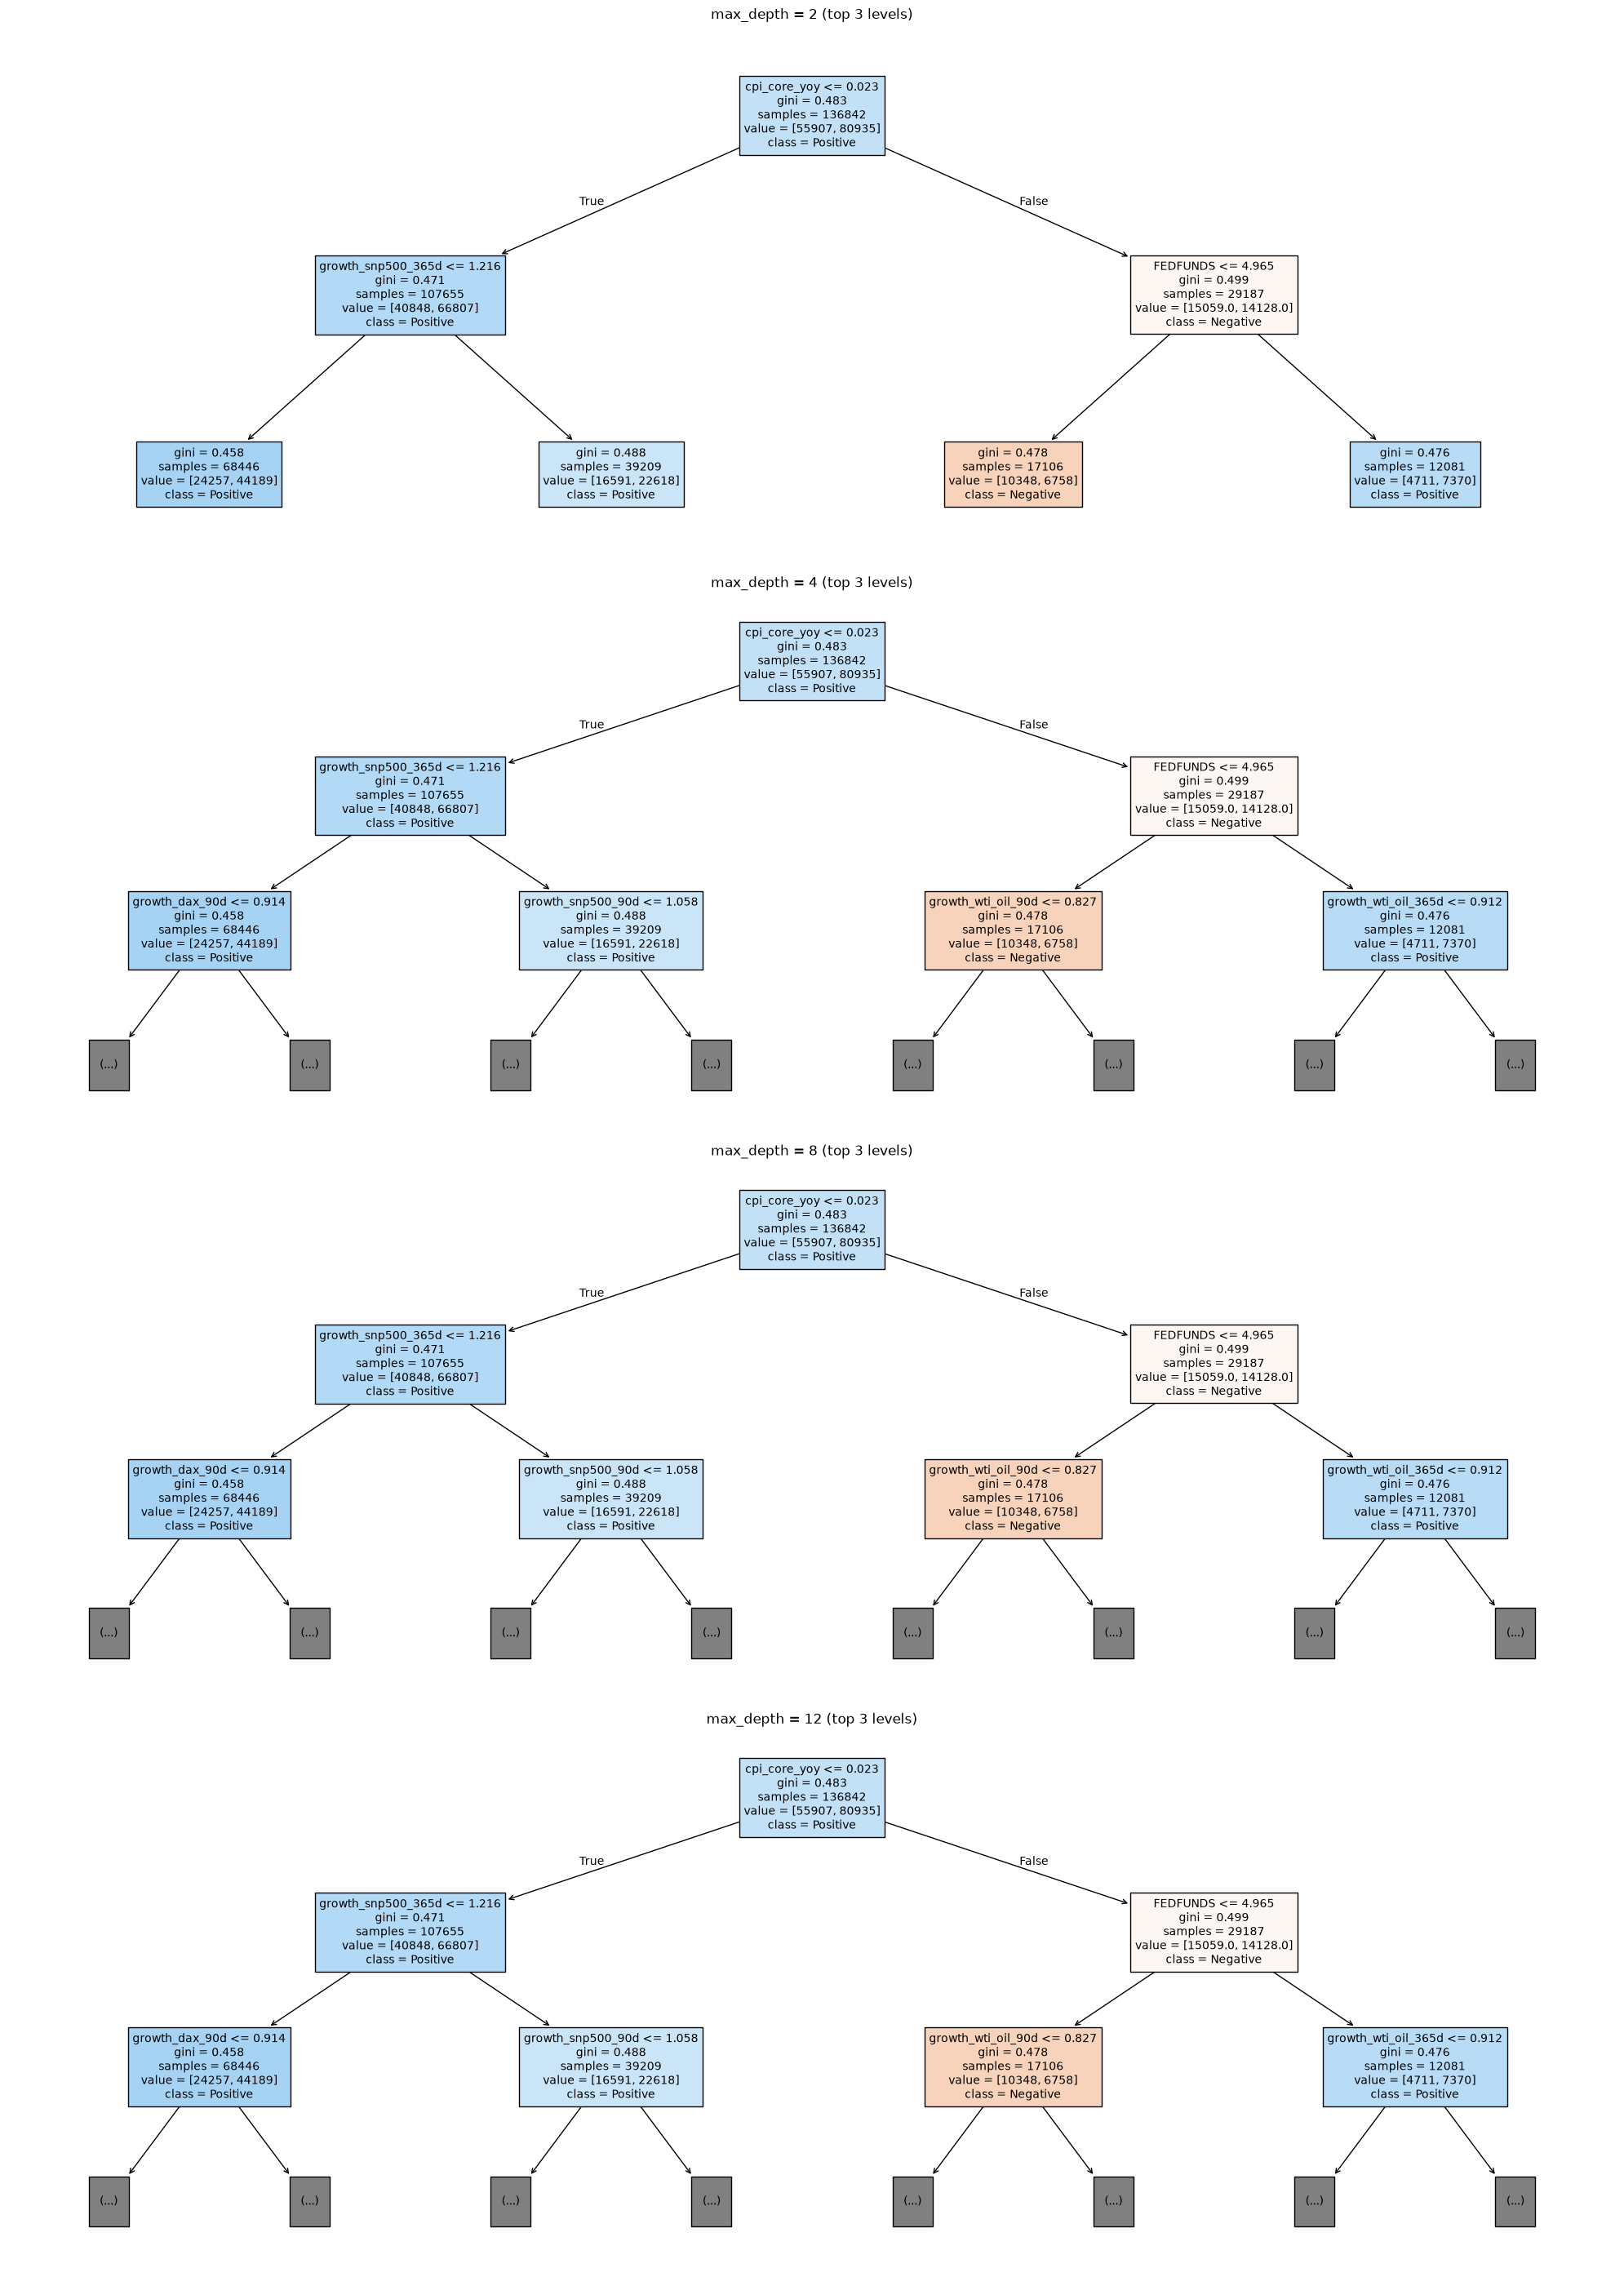

In [31]:
depths_to_plot = [2, 4, 8, 12]

fig, axes = plt.subplots(len(depths_to_plot), 1, figsize=(20, 7 * len(depths_to_plot)))

for ax, depth in zip(axes, depths_to_plot):
    plot_tree(
        trees[depth],
        max_depth=2,  # mostra só os 3 primeiros níveis
        feature_names=list(X_tr),
        class_names=["Negative", "Positive"],
        filled=True,
        fontsize=10,
        ax=ax,
    )
    ax.set_title(f"max_depth = {depth} (top 3 levels)")

plt.tight_layout()
plt.show()


#### **Validation curve: metric x hyperparameter**

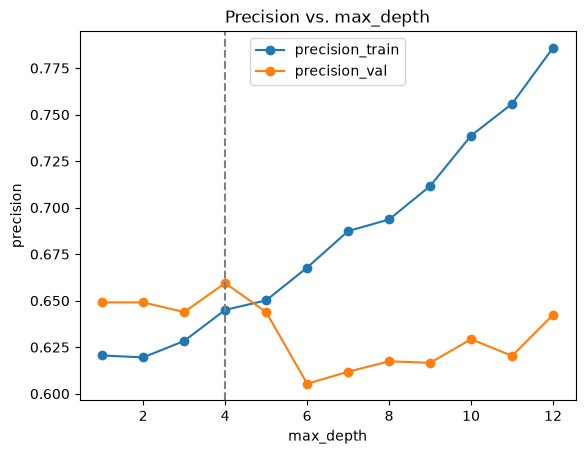

In [32]:
ax = df_tuning[["precision_train", "precision_val"]].plot(
    marker="o", title="Precision vs. max_depth", ylabel="precision"
)
ax.axvline(best_max_depth, linestyle="--", color="gray")


#### **Full train and test splitting**

In [33]:
dt_best = DecisionTreeClassifier(max_depth=best_max_depth, random_state=42)
dt_best.fit(X_train, y_train)  # X_train from question 03 = train + val

df_new["pred6_clf_best"] = dt_best.predict(X_all)

PREDICTIONS = [k for k in df_new.keys() if k.startswith("pred")]

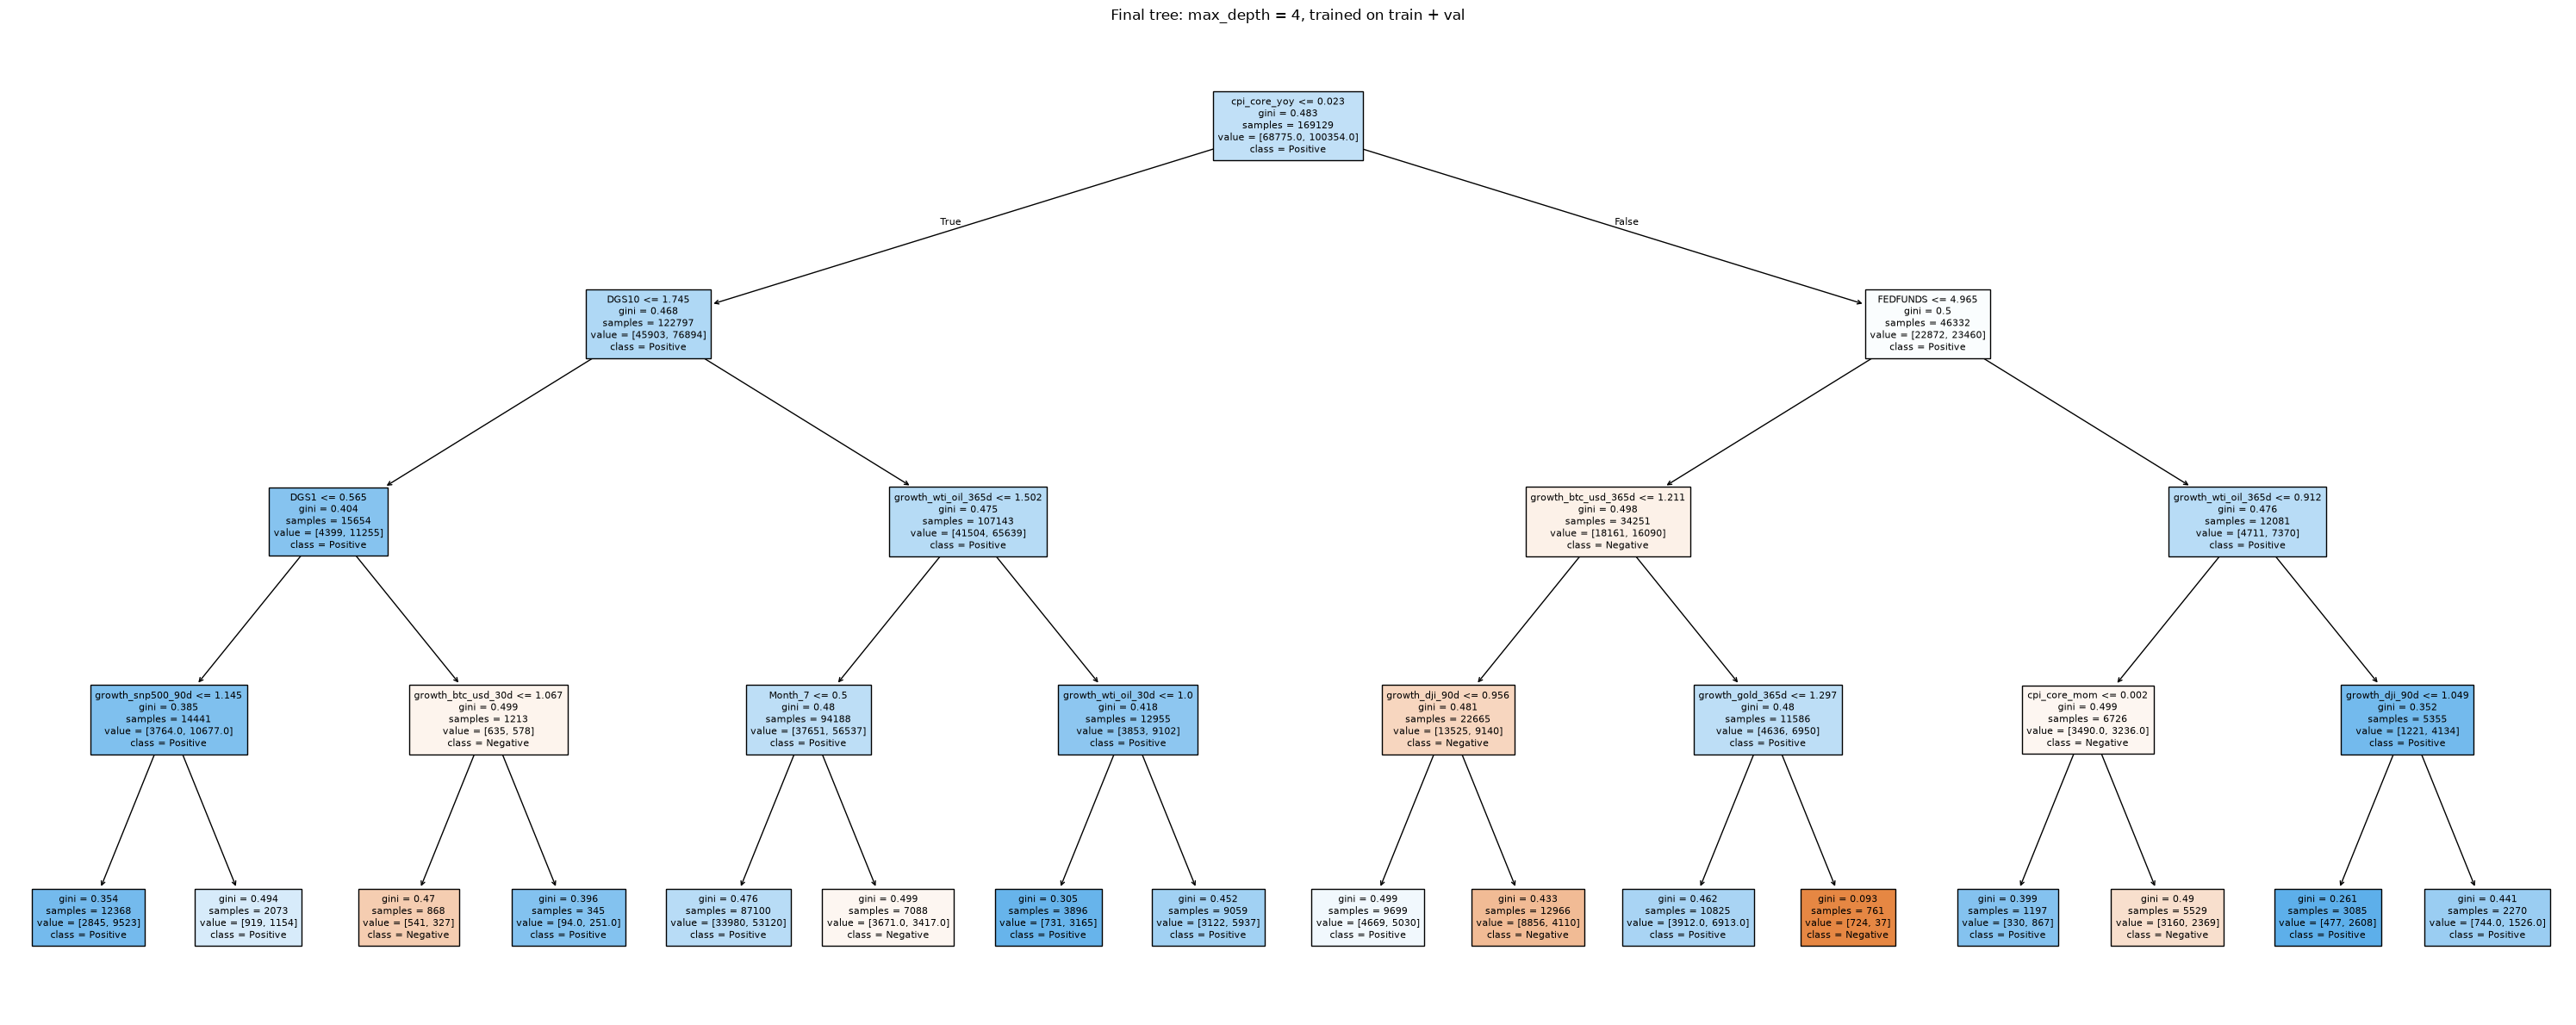

In [34]:
fig, ax = plt.subplots(figsize=(30, 12))

plot_tree(
    dt_best,
    feature_names=list(X_train),
    class_names=["Negative", "Positive"],
    filled=True,
    fontsize=8,
    ax=ax,
)
ax.set_title(f"Final tree: max_depth = {best_max_depth}, trained on train + val")

plt.tight_layout()
plt.show()

In [35]:
df_test = df_new[is_test]

precision_by_pred = pd.Series(
    {pred: precision_score(df_test[to_predict], df_test[pred]) for pred in PREDICTIONS},
    name="precision_test",
).sort_values(ascending=False)

precision_by_pred.round(4)


pred6_clf_best                  0.6292
pred5_dt_10                     0.5912
pred3_manual_dgs10_5            0.5877
pred1_manual_prev_g1            0.5787
pred2_manual_prev_g1_and_snp    0.5726
pred0_manual_cci                0.5646
pred4_manual_dgs10_fedfunds     0.5025
Name: precision_test, dtype: float64

> **Answer: The optimal value for `max_depth` is 4, presenting a precision of 0.629 on the test set.**

## **Question 05**

### **A. Scope and corrected targets**

**Question:** the tree of Question 4 opens with splits on inflation and interest rates. Do macro regimes, defined from those same variables, show where one tree works well and where it does not?

**Procedure:** data since 2000 and the same split dates as in the previous questions, on copies. The date on which each target becomes known is 30 observations ahead of the same ticker. A row is kept in a set only if its target is known inside that set.

**Result to examine:** the dates and the size of each set.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import recall_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import export_text

# copies: the variables of the previous questions are left untouched
q5 = df_new[["Date", "Ticker", to_predict]].copy()
X_q5 = X_all.copy()
y_q5 = q5[to_predict]

split_bounds = df_new.groupby("split")["Date"].agg(["min", "max"]).loc[["train", "val", "test"]]
TRAIN_END = split_bounds.loc["train", "max"]
VAL_END = split_bounds.loc["val", "max"]

# date on which the target becomes known: 30 observations ahead of the same ticker, in date order
q5["target_date"] = q5.sort_values(["Ticker", "Date"]).groupby("Ticker")["Date"].shift(-30)

q5_train = (q5["Date"] <= TRAIN_END) & (q5["target_date"] <= TRAIN_END)
q5_val = (q5["Date"] > TRAIN_END) & (q5["Date"] <= VAL_END) & (q5["target_date"] <= VAL_END)
q5_full_train = (q5["Date"] <= VAL_END) & (q5["target_date"] <= VAL_END)
q5_test = (q5["Date"] > VAL_END) & q5["target_date"].notna()

sets = {"train": q5_train, "validation": q5_val, "train + validation": q5_full_train, "test": q5_test}

pd.DataFrame({
    "first_date": {name: q5.loc[mask, "Date"].min().date() for name, mask in sets.items()},
    "last_date": {name: q5.loc[mask, "Date"].max().date() for name, mask in sets.items()},
    "rows": {name: int(mask.sum()) for name, mask in sets.items()},
})

,first_date,last_date,rows
train,2000-01-03,2018-08-02,135882
validation,2018-09-14,2022-08-04,31297
train + validation,2000-01-03,2022-08-04,168139
test,2022-09-16,2026-08-07,32173


### **B. Global decision tree baseline**

**Purpose:** one tree is the reference for the whole section. It is fitted twice with the same settings: on train, to be evaluated on validation, and on train + validation, to be evaluated on test.

**Procedure:** all the original classification features, `max_depth=4`, `min_samples_leaf=1`, `criterion="gini"`, `random_state=42` and a threshold of 0.50.

**Result to examine:** the first splits of each tree, and precision, recall and share of positive predictions on validation and on test.

In [ ]:
BASELINE_PARAMS = {"max_depth": 4, "min_samples_leaf": 1, "criterion": "gini", "random_state": 42}
THRESHOLD = 0.5


def predict_positive(tree, X):
    """1 where the predicted probability of class 1 is above the threshold."""
    return (tree.predict_proba(X)[:, 1] > THRESHOLD).astype(int)


def score_predictions(y_true, y_pred):
    """Counts, precision and recall. Precision is NaN (undefined) without positive predictions."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return {
        "observations": len(y_true),
        "actual_positive_pct": y_true.mean() * 100,
        "positive_predictions": int(y_pred.sum()),
        "precision": precision_score(y_true, y_pred) if y_pred.any() else np.nan,
        "recall": recall_score(y_true, y_pred) if y_true.any() else np.nan,
    }


# evaluated set -> (description of the tree, rows it is fitted on)
STAGES = {
    "validation": ("fitted on train", q5_train),
    "test": ("fitted on train + validation", q5_full_train),
}

trees, pred = {}, {}
rows = []

for eval_name, (fit_name, fit_mask) in STAGES.items():
    tree = DecisionTreeClassifier(**BASELINE_PARAMS).fit(X_q5[fit_mask], y_q5[fit_mask])
    trees[eval_name] = tree
    pred[eval_name] = pd.Series(predict_positive(tree, X_q5[sets[eval_name]]), index=q5.index[sets[eval_name]])

    print(f"tree {fit_name}, first levels:")
    print(export_text(tree, feature_names=list(X_q5), max_depth=1))
    rows.append({"tree": fit_name, "evaluated on": eval_name,
                 **score_predictions(y_q5[sets[eval_name]], pred[eval_name])})

df_global = pd.DataFrame(rows).set_index(["tree", "evaluated on"])
df_global.round(3)

tree fitted on train, first levels:
|--- cpi_core_yoy <= 0.02
|   |--- growth_snp500_365d <= 1.24
|   |   |--- truncated branch of depth 3
|   |--- growth_snp500_365d >  1.24
|   |   |--- truncated branch of depth 3
|--- cpi_core_yoy >  0.02
|   |--- FEDFUNDS <= 4.96
|   |   |--- truncated branch of depth 3
|   |--- FEDFUNDS >  4.96
|   |   |--- truncated branch of depth 3

tree fitted on train + validation, first levels:
|--- cpi_core_yoy <= 0.02
|   |--- DGS10 <= 1.75
|   |   |--- truncated branch of depth 3
|   |--- DGS10 >  1.75
|   |   |--- truncated branch of depth 3
|--- cpi_core_yoy >  0.02
|   |--- cpi_core_yoy <= 0.03
|   |   |--- truncated branch of depth 3
|   |--- cpi_core_yoy >  0.03
|   |   |--- truncated branch of depth 3



,,observations,actual_positive_pct,positive_predictions,precision,recall
tree,evaluated on,,,,,
fitted on train,validation,31297,61.242,16817,0.647,0.568
fitted on train + validation,test,32173,58.764,12442,0.553,0.364


**Question:** where do the evaluated rows go at the root of the tree, and what does the tree predict on each side?

**Procedure:** for each tree, the rule of the root split divides the evaluated rows into the left branch (rule satisfied) and the right branch. For each branch the table has the share of the evaluated rows, the share of actual positives and the share of rows for which the tree predicts growth.

**Result to examine:** the percentage of the validation and test rows that follows the right branch, and how often the tree predicts growth there.

In [113]:
rows = []
for eval_name, tree in trees.items():
    feature = X_q5.columns[tree.tree_.feature[0]]
    threshold = tree.tree_.threshold[0]
    idx = q5.index[sets[eval_name]]
    goes_right = (X_q5.loc[idx, feature] > threshold).to_numpy()

    for branch_name, in_branch in [("left", ~goes_right), ("right", goes_right)]:
        idx_b = idx[in_branch]
        row = {
            "tree": STAGES[eval_name][0],
            "root split": f"{feature} <= {threshold:.4f}",
            "evaluated on": eval_name,
            "branch": branch_name,
            "rows_pct": len(idx_b) / len(idx) * 100,
        }
        if len(idx_b):
            scores = score_predictions(y_q5[idx_b], pred[eval_name][idx_b])
            row.update({
                "actual_positive_pct": scores["actual_positive_pct"],
                "predicted_positive_pct": pred[eval_name][idx_b].mean() * 100,
                "precision": scores["precision"],
                "recall": scores["recall"],
            })
        rows.append(row)

(
    pd.DataFrame(rows)
    .set_index(["tree", "root split", "evaluated on", "branch"])
    .round({"rows_pct": 1, "actual_positive_pct": 1, "predicted_positive_pct": 1, "precision": 3, "recall": 3})
)


rows_pct  \
tree                         root split             evaluated on branch             
fitted on train              cpi_core_yoy <= 0.0230 validation   left        54.7   
                                                                 right       45.3   
fitted on train + validation cpi_core_yoy <= 0.0228 test         left         0.0   
                                                                 right      100.0   

                                                                         actual_positive_pct  \
tree                         root split             evaluated on branch                        
fitted on train              cpi_core_yoy <= 0.0230 validation   left                   64.9   
                                                                 right                  56.8   
fitted on train + validation cpi_core_yoy <= 0.0228 test         left                    NaN   
                                                                 right                  58.8   

                                                                         predicted_positive_pct  \
tree                         root split             evaluated on branch                           
fitted on train              cpi_core_yoy <= 0.0230 validation   left                      98.2   
                                                                 right                      0.0   
fitted on train + validation cpi_core_yoy <= 0.0228 test         left                       NaN   
                                                                 right                     38.7   

                                                                         precision  \
tree                         root split             evaluated on branch              
fitted on train              cpi_core_yoy <= 0.0230 validation   left        0.647   
                                                                 right         NaN   
fitted on train + validation cpi_core_yoy <= 0.0228 test         left          NaN   
                                                                 right       0.553   

                                                                         recall  
tree                         root split             evaluated on branch          
fitted on train              cpi_core_yoy <= 0.0230 validation   left     0.979  
                                                                 right    0.000  
fitted on train + validation cpi_core_yoy <= 0.0228 test         left       NaN  
                                                                 right    0.364

### **C. Macro variables, one row per date**

**Purpose:** restrict the regimes to the macro variables behind the hypothesis. The first two levels of the Question 4 tree use `cpi_core_yoy`, `DGS10` and `FEDFUNDS`.

**Procedure:** the three series in their original values, taken from `df_new`, before the `fillna(0)` of the feature matrix. They are shared by all tickers, so the table has one row per date, the median across tickers; this keeps dates with more tickers from weighing more.

**Result to examine:** the dates covered by each period.

In [114]:
MACRO_REGIME = ["cpi_core_yoy", "DGS10", "FEDFUNDS"]

macro = df_new.groupby("Date")[MACRO_REGIME].median().reset_index()
assert macro[MACRO_REGIME].notna().all().all()  # no date without these macro values

macro["period"] = np.select(
    [macro["Date"] <= TRAIN_END, macro["Date"] <= VAL_END], ["train", "validation"], default="test"
)

macro.groupby("period")["Date"].agg(["min", "max", "count"]).loc[["train", "validation", "test"]]

,min,max,count
period,,,
train,2000-01-03,2018-09-13,4855
validation,2018-09-14,2022-09-15,1041
test,2022-09-16,2026-09-18,1040


### **D. Regimes with KMeans**

**Purpose:** identify two macro regimes with a single definition, used for every set.

**Procedure:** `StandardScaler` → `KMeans(n_clusters=2, random_state=42, n_init=20)`, fitted on the train dates only and then applied to all dates. Cluster numbers are arbitrary, so the identifiers are ordered by the average policy rate in train: 0 is the regime with the lower `FEDFUNDS`.

**Result to examine:** the number of dates of each regime in train, validation and test.

In [118]:
macro.loc[train_dates]

,Date,cpi_core_yoy,DGS10,FEDFUNDS,period,regime
0,2000-01-03,0.021071,6.58,5.45,train,1
1,2000-01-04,0.021071,6.49,5.45,train,1
2,2000-01-05,0.021071,6.62,5.45,train,1
3,2000-01-06,0.021071,6.57,5.45,train,1
4,2000-01-07,0.021071,6.52,5.45,train,1
...,...,...,...,...,...,...
4850,2018-09-07,0.021977,2.94,1.95,train,0
4851,2018-09-10,0.021977,2.94,1.95,train,0
4852,2018-09-11,0.021977,2.98,1.95,train,0
4853,2018-09-12,0.021977,2.97,1.95,train,0


In [115]:
train_dates = macro["period"].eq("train")

regime_model = make_pipeline(
    StandardScaler(),
    KMeans(n_clusters=2, random_state=42, n_init=20),
)
regime_model.fit(macro.loc[train_dates, MACRO_REGIME])

cluster = pd.Series(
    regime_model.predict(macro[MACRO_REGIME]),
    index=macro.index,
)

# identifiers ordered by the average FEDFUNDS in train
order = (
    macro.loc[train_dates, "FEDFUNDS"]
    .groupby(cluster[train_dates])
    .mean()
    .sort_values()
    .index
)
macro["regime"] = cluster.map(
    {old: new for new, old in enumerate(order)}
)

pd.crosstab(macro["period"], macro["regime"]).loc[["train", "validation", "test"]]

regime,0,1
period,,
train,3114,1741
validation,683,358
test,0,1040


In [119]:
cluster

0       0
1       0
2       0
3       0
4       0
       ..
6931    0
6932    0
6933    0
6934    0
6935    0
Length: 6936, dtype: int32

### **E. The two regimes**

**Question:** what distinguishes the two regimes?

**Procedure:** average inflation and interest rates of each regime over the train dates, in the original units of the dataset.

**Result to examine:** the macro profile that names each regime. The numbers 0 and 1 are only identifiers.

In [116]:
df_regime_profile = (
    macro.loc[train_dates]
    .groupby("regime")[MACRO_REGIME]
    .mean()
)

# names given from the profile above
REGIME_NAMES = {0: "lower inflation and rates", 1: "higher inflation and rates"}
df_regime_profile["name"] = df_regime_profile.index.map(REGIME_NAMES)

df_regime_profile.round(4)

,cpi_core_yoy,DGS10,FEDFUNDS,name
regime,,,,
0,0.0176,2.7932,0.5057,lower inflation and rates
1,0.0241,4.7871,4.0020,higher inflation and rates


**Question:** where are the two centroids, and how do the dates sit around them?

**Procedure:** the three pairs of macro variables in the original units. Filled points are the train dates, used to fit the model; hollow points are the validation and test dates, only assigned to the nearest centroid. The crosses are the centroids.

**Result to examine:** how separated the two groups are in train, and whether the later dates stay inside the region covered by the train dates.


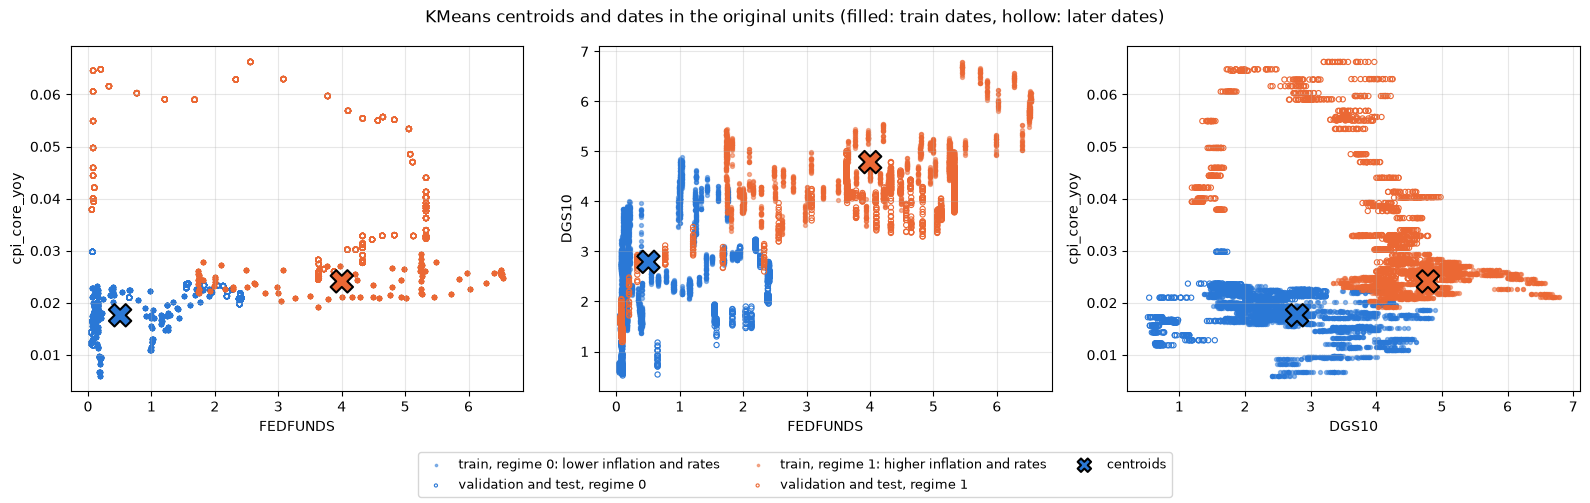

,cpi_core_yoy,DGS10,FEDFUNDS
regime,,,
0,0.0176,2.7932,0.5057
1,0.0241,4.7871,4.0020


In [120]:
REGIME_COLORS = {0: "#2a78d6", 1: "#eb6834"}

# centroids back in the original units, in the same order as the regime identifiers
scaler_step = regime_model.named_steps["standardscaler"]
kmeans_step = regime_model.named_steps["kmeans"]
centroids = pd.DataFrame(
    scaler_step.inverse_transform(kmeans_step.cluster_centers_), columns=MACRO_REGIME
).loc[order].reset_index(drop=True).rename_axis("regime")

pairs = [("FEDFUNDS", "cpi_core_yoy"), ("FEDFUNDS", "DGS10"), ("DGS10", "cpi_core_yoy")]
later_dates = ~train_dates

fig, axes = plt.subplots(1, len(pairs), figsize=(16, 5))

for ax, (x, y) in zip(axes, pairs):
    for regime, name in REGIME_NAMES.items():
        in_regime = macro["regime"] == regime
        ax.scatter(macro.loc[train_dates & in_regime, x], macro.loc[train_dates & in_regime, y],
                   s=8, alpha=0.5, color=REGIME_COLORS[regime], label=f"train, regime {regime}: {name}")
        ax.scatter(macro.loc[later_dates & in_regime, x], macro.loc[later_dates & in_regime, y],
                   s=14, facecolors="none", edgecolors=REGIME_COLORS[regime], linewidths=0.8,
                   label=f"validation and test, regime {regime}")
    ax.scatter(centroids[x], centroids[y], marker="X", s=260, color=[REGIME_COLORS[r] for r in centroids.index],
               edgecolors="black", linewidths=1.5, label="centroids", zorder=5)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.grid(alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=9, markerscale=0.6)
fig.suptitle("KMeans centroids and dates in the original units (filled: train dates, hollow: later dates)")

plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.show()

centroids.round(4)


**Question:** how are these contexts distributed over time?

**Procedure:** core inflation, the 10-year yield and the policy rate over all dates since 2000, coloured by regime. The dashed lines mark the end of train and the end of validation.

**Result to examine:** whether the regimes form long periods that come back, and which regime the validation and test dates fall in.

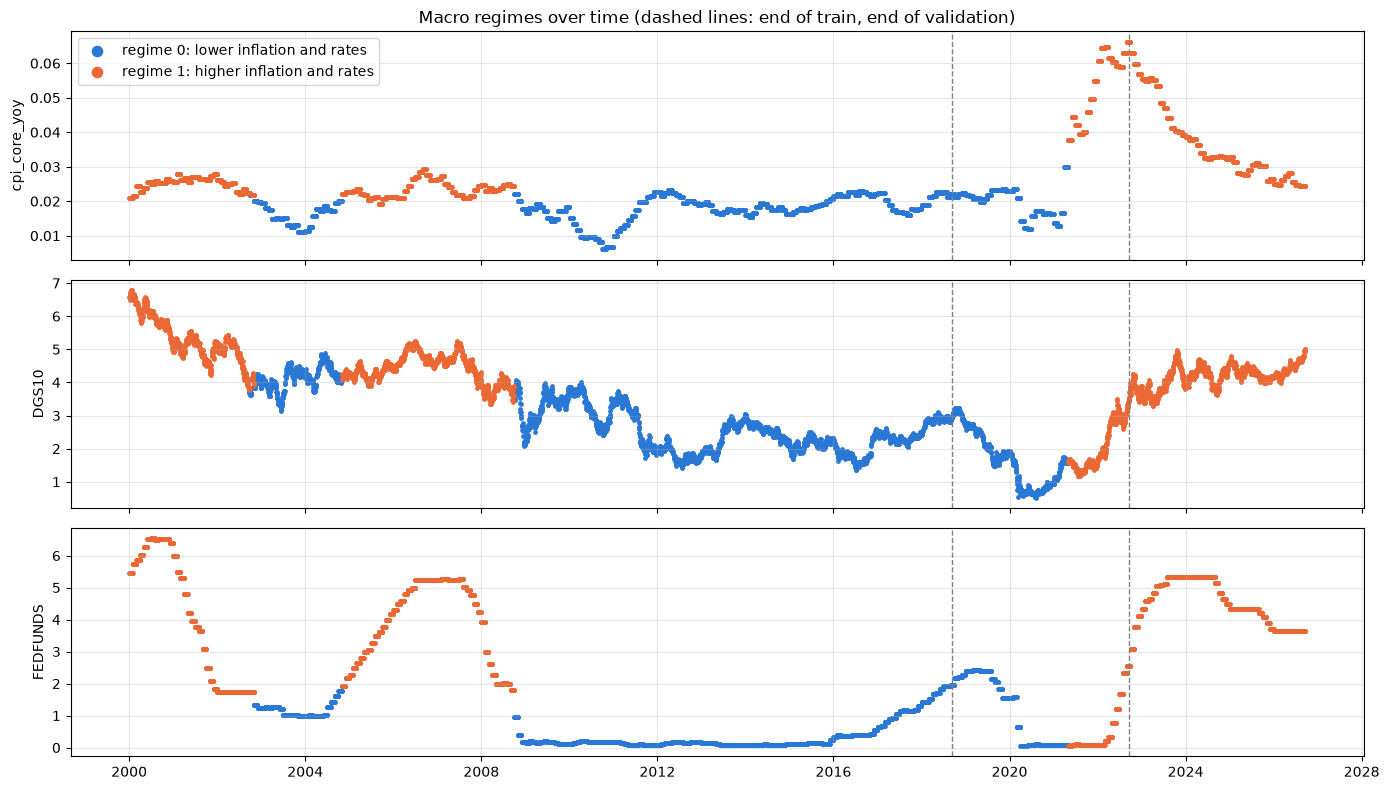

In [121]:
REGIME_COLORS = {0: "#2a78d6", 1: "#eb6834"}

fig, axes = plt.subplots(len(MACRO_REGIME), 1, figsize=(14, 8), sharex=True)

for ax, feature in zip(axes, MACRO_REGIME):
    for regime, name in REGIME_NAMES.items():
        part = macro[macro["regime"] == regime]
        ax.scatter(part["Date"], part[feature], s=6, color=REGIME_COLORS[regime], label=f"regime {regime}: {name}")
    for boundary in [TRAIN_END, VAL_END]:
        ax.axvline(boundary, linestyle="--", color="gray", linewidth=1)
    ax.set_ylabel(feature)
    ax.grid(alpha=0.3)

axes[0].set_title("Macro regimes over time (dashed lines: end of train, end of validation)")
axes[0].legend(markerscale=3, loc="upper left")

plt.tight_layout()
fig.savefig("macro_regimes_over_time.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

### **F. Main result: the same tree by regime**

**Question:** how does the behaviour of the classifier change from one macro context to the other?

**Procedure:** the regime of each date is attached to the stock rows of that date, and the predictions already made on validation and on test are split by regime. Assigning regimes does not change any prediction. The share of actual positives helps to read the precision, and the counts show how much data is behind each number. Precision is shown as undefined when there are no positive predictions.

**Result to examine:** observations, actual positives, positive predictions, precision and recall in each regime present in each set. The overall rows are in `df_global`.

In [ ]:
q5["regime"] = q5["Date"].map(
    macro.set_index("Date")["regime"]
)


def regime_table(set_name):
    """Metrics of the global tree in each regime present in the set."""
    idx = q5.index[sets[set_name]]
    regime = q5.loc[idx, "regime"].astype(int)

    rows = []
    for r in sorted(regime.unique()):
        idx_r = idx[regime == r]
        rows.append({
            "set": set_name,
            "regime": f"{r}: {REGIME_NAMES[r]}",
            **score_predictions(y_q5[idx_r], pred[set_name][idx_r]),
        })
    return pd.DataFrame(rows)


df_regime_metrics = pd.concat([regime_table("validation"), regime_table("test")]).set_index(["set", "regime"]).round(3)
df_regime_metrics["precision"] = (
    df_regime_metrics["precision"].astype(object).where(df_regime_metrics["precision"].notna(), "undefined")
)
df_regime_metrics

observations  actual_positive_pct  positive_predictions  precision  recall
set        regime                                                                                                   
validation 0: lower inflation and rates          21079               65.088                 16817      0.647   0.793
           1: higher inflation and rates         10218               53.308                     0  undefined   0.000
test       1: higher inflation and rates         32173               58.764                 12442      0.553   0.364

### **G. Complement: persistence of the regimes**

**Question:** how persistent are these states from one trading date to the next?

**Procedure:** the sequence of regimes over the train + validation dates, in date order. Each pair of consecutive dates is a transition, and each count is divided by the number of departures from its state.

**Result to examine:** the 2×2 matrix of transition probabilities and the number of changes of regime. This is a first-order approximation; building the matrix does not show that the sequence has the Markov property.

In [ ]:
history = macro[macro["period"].isin(["train", "validation"])].sort_values("Date")
sequence = history["regime"].to_numpy()

transition_probs = pd.crosstab(
    pd.Series(sequence[:-1], name="from"), pd.Series(sequence[1:], name="to"), normalize="index"
)
labels = [f"{r}: {REGIME_NAMES[r]}" for r in transition_probs.index]
transition_probs.index = pd.Index(labels, name="from")
transition_probs.columns = pd.Index(labels, name="to")

print(f"changes of regime in {len(sequence)} dates: {int((sequence[1:] != sequence[:-1]).sum())}")
transition_probs.round(4)

changes of regime in 5896 dates: 8


to,0: lower inflation and rates,1: higher inflation and rates
from,,
0: lower inflation and rates,0.9989,0.0011
1: higher inflation and rates,0.0019,0.9981


### **H. Final answer**

> **Answer:** instead of adding indicators, I looked at the macro context in which the same tree is applied. Two regimes, identified with KMeans on core inflation, the 10-year yield and the policy rate, show that the behaviour of the classifier changes from one context to the other, and that the whole test period sits in a single context.
>
> - **The tree already uses macro variables in its first splits.** The root splits on `cpi_core_yoy` at about 0.023, and the next level uses `FEDFUNDS`, `DGS10` or `cpi_core_yoy` again. 45.3% of the validation rows and 100% of the test rows follow the right branch of the root.
> - **Regimes.** On the train dates, regime 0 has core inflation of 1.8%, `DGS10` of 2.8 and `FEDFUNDS` of 0.5; regime 1 has 2.4%, 4.8 and 4.0. The chart shows that regime 1 comes back in different periods: the early 2000s, 2004 to 2008 and from May 2021 on. It holds 1,741 of the 4,855 train dates, 358 of the 1,041 validation dates and all 1,040 test dates.
> - **Main result, validation.** In regime 0 (21,079 rows, 65.1% positive) the tree has precision 0.647 and recall 0.793. In regime 1 (10,218 rows, 53.3% positive) it makes no positive prediction: precision is undefined and recall is 0. The overall recall of 0.568 is the mix of these two situations.
> - **Test (exploratory, this test set had already been consulted).** All 32,173 test rows are in regime 1, so the two regimes cannot be compared there. The tree refitted on train + validation predicts growth for 38.7% of those rows while 58.8% are positive: precision 0.553, below the share of positives, and recall 0.364. The concentration of the test set in one context helps to read its lower recall.
> - **Persistence.** Over the 5,896 train + validation dates there are 8 changes of regime. A date in regime 0 is followed by another one with probability 0.9989, and a date in regime 1 with probability 0.9981. This is a first-order description of persistence; it does not show that the sequence has the Markov property.
> - **Limitations.** The names describe the train profile. KMeans assigns each later date to the nearest centroid, so the regime-1 validation dates (May 2021 to September 2022) are there because of inflation far above anything in train, while the policy rate was still near zero for most of that time. Validation and test are scored by two fits of the tree, so the regime-1 numbers of the two sets come from different models. Only one regime appears in the test set, and assigning regimes is a diagnostic: it does not change any prediction.
>
> What this supports: one overall metric hides two very different behaviours of the same tree, and the lower recall on test goes together with the test being entirely in one macro context. It does not, by itself, show that data is missing.
